# Training demo

I compare the sweep, then inspect which family scores went into the blend.

In [1]:
from pathlib import Path
import json
import os
import sys

# Read the saved OOF results so this notebook does not rerun the sweep.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from data import clean_train, load
from metrics import threshold_for_fpr

runs_json = json.loads((ROOT / "reports/experiments.json").read_text())
runs = pd.DataFrame(runs_json["candidates"])
oof = pd.read_csv(ROOT / "reports/oof_scores.csv")
train_clean, _ = clean_train(load("train"))

In [2]:
# Sort by the metric used to choose the advanced model.
display(runs.sort_values("recall_at_1pct_fpr", ascending=False)[
    ["id", "features", "model", "params", "components", "roc_auc",
     "recall_at_1pct_fpr", "recall_at_0.1pct_fpr", "seconds"]
].reset_index(drop=True))
display(pd.DataFrame([runs_json["selected"]]))
display(pd.DataFrame([{"check": name, **values}
                      for name, values in runs_json["checks"].items()]))

,id,features,model,params,components,roc_auc,recall_at_1pct_fpr,recall_at_0.1pct_fpr,seconds
0,18,advanced,blend,{},"[[3, 0.25], [7, 0.75]]",0.9753,0.7021,0.3444,NaN
1,20,advanced,blend,{},"[[3, 0.5], [7, 0.25], [11, 0.25]]",0.9763,0.6992,0.2984,NaN
2,21,advanced,blend,{},"[[3, 0.5], [7, 0.5]]",0.9756,0.6979,0.3466,NaN
3,17,advanced,blend,{},"[[3, 0.25], [7, 0.5], [11, 0.25]]",0.9757,0.6937,0.2804,NaN
4,19,advanced,blend,{},"[[3, 0.5], [11, 0.5]]",0.9758,0.6928,0.2804,NaN
5,23,advanced,blend,{},"[[3, 0.75], [7, 0.25]]",0.9753,0.6888,0.3491,NaN
6,7,advanced,lightgbm,"{'n_estimators': 800, 'learning_rate': 0.05, '...","[[7, 1.0]]",0.9733,0.6886,0.1947,74.0
7,22,advanced,blend,{},"[[3, 0.75], [11, 0.25]]",0.9755,0.6883,0.3092,NaN
8,16,advanced,blend,{},"[[3, 0.25], [7, 0.25], [11, 0.5]]",0.9751,0.6883,0.2602,NaN
9,5,advanced,lightgbm,"{'n_estimators': 300, 'learning_rate': 0.05, '...","[[5, 1.0]]",0.9724,0.6881,0.0970,33.2


,id,features,model,params,components,roc_auc,recall_at_1pct_fpr,recall_at_0.1pct_fpr
0,18,advanced,blend,{},"[[3, 0.25], [7, 0.75]]",0.9753,0.7021,0.3444


,check,roc_auc,recall_at_1pct_fpr,recall_at_0.1pct_fpr
0,baseline_random_folds,0.9734,0.7400,0.5071
1,baseline_uncleaned_train,0.9562,0.6016,0.1397


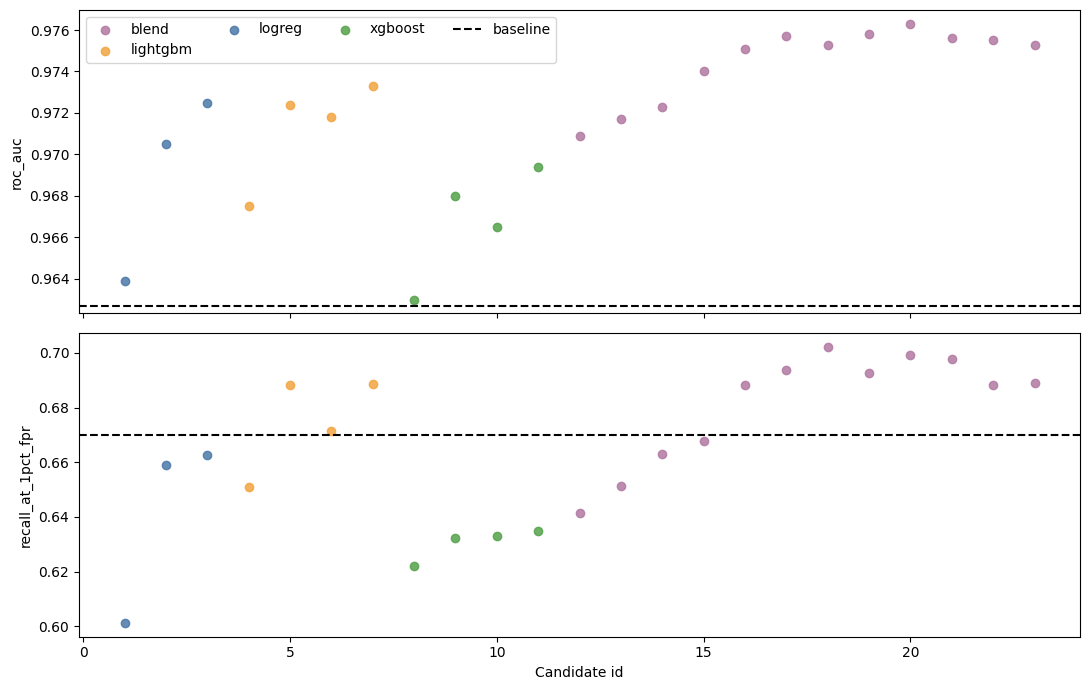

In [3]:
# The horizontal lines show the baseline while the dots show advanced candidates.
colors = {"logreg": "#4c78a8", "lightgbm": "#f2a541",
          "xgboost": "#54a24b", "blend": "#b279a2"}
baseline = runs[runs.features == "baseline"].iloc[0]
advanced_runs = runs[runs.features == "advanced"]
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for model_name, group in advanced_runs.groupby("model"):
    for axis, metric in zip(axes, ("roc_auc", "recall_at_1pct_fpr")):
        axis.scatter(group.id, group[metric], color=colors[model_name],
                     label=model_name, alpha=0.85)
for axis, metric in zip(axes, ("roc_auc", "recall_at_1pct_fpr")):
    axis.axhline(baseline[metric], color="black", linestyle="--", label="baseline")
    axis.set_ylabel(metric)
axes[0].legend(ncol=4)
axes[-1].set_xlabel("Candidate id")
fig.tight_layout()
plt.show()
plt.close(fig)

I compare each family with the same grouped-fold baseline reference; the recall panel is the selection metric.

In [4]:
# Convert candidate ids back to readable family weights.
family_by_id = runs.set_index("id").model.to_dict()
blend_rows = []
for row in runs[runs.model == "blend"].to_dict("records"):
    weights = {name: 0.0 for name in ("logreg", "lightgbm", "xgboost")}
    for candidate_id, weight in row["components"]:
        weights[family_by_id[candidate_id]] = weight
    blend_rows.append({"id": row["id"], **weights, "roc_auc": row["roc_auc"],
                       "recall_at_1pct_fpr": row["recall_at_1pct_fpr"],
                       "recall_at_0.1pct_fpr": row["recall_at_0.1pct_fpr"]})
blend_table = pd.DataFrame(blend_rows).sort_values(
    "recall_at_1pct_fpr", ascending=False)
display(blend_table.reset_index(drop=True))

selected = runs_json["selected"]
display(pd.DataFrame([selected]))
correlation = pd.DataFrame(runs_json["family_best_correlation"])
display(correlation)

,id,logreg,lightgbm,xgboost,roc_auc,recall_at_1pct_fpr,recall_at_0.1pct_fpr
0,18,0.25,0.75,0.00,0.9753,0.7021,0.3444
1,20,0.50,0.25,0.25,0.9763,0.6992,0.2984
2,21,0.50,0.50,0.00,0.9756,0.6979,0.3466
3,17,0.25,0.50,0.25,0.9757,0.6937,0.2804
4,19,0.50,0.00,0.50,0.9758,0.6928,0.2804
5,23,0.75,0.25,0.00,0.9753,0.6888,0.3491
6,16,0.25,0.25,0.50,0.9751,0.6883,0.2602
7,22,0.75,0.00,0.25,0.9755,0.6883,0.3092
8,15,0.25,0.00,0.75,0.9740,0.6677,0.2489
9,14,0.00,0.75,0.25,0.9723,0.6630,0.1957


,id,features,model,params,components,roc_auc,recall_at_1pct_fpr,recall_at_0.1pct_fpr
0,18,advanced,blend,{},"[[3, 0.25], [7, 0.75]]",0.9753,0.7021,0.3444


,logreg,lightgbm,xgboost
logreg,1.000,0.943,0.941
lightgbm,0.943,1.000,0.982
xgboost,0.941,0.982,1.000


In [5]:
# Give each score column its own OOF cutoff at 1% false-positive rate.
labels = train_clean.label.to_numpy()
score_columns = {"logreg": oof.logreg.to_numpy(),
                 "lightgbm": oof.lightgbm.to_numpy(),
                 "blend": oof.advanced.to_numpy()}
threshold_rows = []
cutoffs = {}
for name, scores in score_columns.items():
    cutoff = threshold_for_fpr(labels, scores, 0.01)
    cutoffs[name] = cutoff
    threshold_rows.append({"model": name, "threshold": cutoff,
                           "val_recall": float((scores[labels == 1] >= cutoff).mean()),
                           "val_fpr": float((scores[labels == 0] >= cutoff).mean())})
display(pd.DataFrame(threshold_rows))

predicted = {name: scores >= cutoffs[name]
             for name, scores in score_columns.items()}
disagreements = []
for label, name in ((1, "phishing"), (0, "legitimate")):
    mask = labels == label
    lr, lgbm = predicted["logreg"][mask], predicted["lightgbm"][mask]
    disagreements.append({
        "class": name, "rows": int(mask.sum()),
        "both": int((lr & lgbm).sum()),
        "logreg_only": int((lr & ~lgbm).sum()),
        "lightgbm_only": int((~lr & lgbm).sum()),
        "neither": int((~lr & ~lgbm).sum()),
        "blend_flagged": int(predicted["blend"][mask].sum()),
    })
display(pd.DataFrame(disagreements))

,model,threshold,val_recall,val_fpr
0,logreg,0.944329,0.662728,0.009866
1,lightgbm,0.998970,0.688577,0.009866
2,blend,0.970851,0.702117,0.009866


,class,rows,both,logreg_only,lightgbm_only,neither,blend_flagged
0,phishing,4062,2442,250,355,1015,2852
1,legitimate,4257,23,19,19,4196,42


A blend is a weighted average of the two probabilities; the selected 25% LR / 75% LightGBM weights came from a 0.25 grid scored on OOF rows. At their own 1% FPR cutoffs, the table shows 250 phishing URLs caught only by LR and 355 only by LightGBM, while the blend catches 2,852 of 4,062; their false positives also differ (19 unique to each, 23 shared). XGBoost correlates 0.982 with LightGBM, so it adds little new ranking signal and gets zero weight in the selected blend. The weights were chosen on these same OOF scores, so this comparison is a little optimistic.

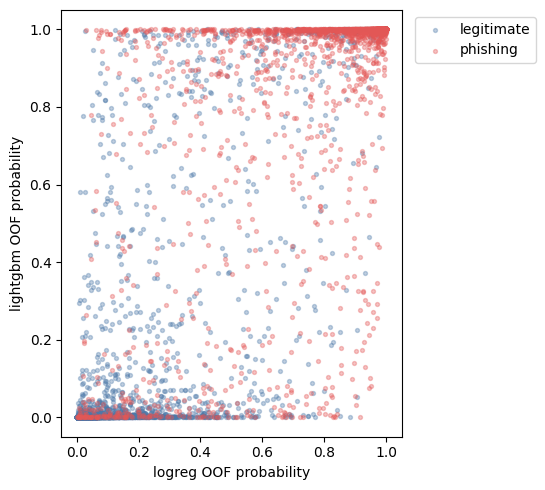

In [6]:
# Compare two selected blend components; if a single won, use the two best families.
component_ids = [candidate_id for candidate_id, _ in selected["components"]]
if len(component_ids) < 2:
    best_families = (runs[(runs.features == "advanced") &
                          (runs.model.isin(("logreg", "lightgbm", "xgboost")))]
                     .sort_values("recall_at_1pct_fpr", ascending=False)
                     .drop_duplicates("model"))
    component_ids = best_families.id.head(2).tolist()
else:
    component_ids = component_ids[:2]
family_names = [family_by_id[i] for i in component_ids]
fig, ax = plt.subplots(figsize=(7, 5))
labels = train_clean.label.to_numpy()
for label, color, name in ((0, "#4c78a8", "legitimate"),
                           (1, "#e45756", "phishing")):
    mask = labels == label
    ax.scatter(oof[family_names[0]][mask], oof[family_names[1]][mask],
               color=color, label=name, alpha=0.35, s=8)
ax.set(xlabel=f"{family_names[0]} OOF probability",
       ylabel=f"{family_names[1]} OOF probability")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout(rect=[0, 0, 0.8, 1])
plt.show()
plt.close(fig)

Blue points are legitimate URLs; red points are phishing URLs.